# Experiment 1: Finding the better basin

**Hypothesis.** As the better basin becomes harder to find, global BO
with expected improvement and CMA-ES may spend too much of their
evaluation budget near the inferior basin. We compare global BO,
CMA-ES, TuRBO-1 and uniform random search over four values of $c$,
with 10 seeds and 50 evaluations per method per seed. These measurements address the baseline part of the hypothesis. Giving
a method more chances to search elsewhere could improve discovery and
leave fewer calls for refinement.

Keep this notebook beside `methods.ipynb` and
`configurations.ipynb`. 

## Objective and search domain

For $x \in [-4,4]^2$ and $c \ge 0$, minimise

$$
f_c(x) = \min\left\{
    1 + \lVert x-a \rVert_2^2,\;
    \lVert x-b \rVert_2^2
    + c\left[\max\left(0, \lVert x-b \rVert_2 - 0.5\right)\right]^2
\right\},
\qquad a = (-2,0),\quad b = (2,0).
$$

Basin A has a local minimum of 1 at $a$. Basin B has the global minimum
of 0 at $b$. Increasing $c$ shrinks the region where $f_c(x)<1$ and increase the steepness of the B branch outside its center.  

## 1. Setup

Install the dependencies in the notebook's Python environment before
running the experiment. The second command needs Git and network access.

```python
%pip install numpy pandas scipy matplotlib scikit-optimize cma torch gpytorch
%pip install git+https://github.com/uber-research/TuRBO.git
```

In [ ]:
from datetime import datetime, timezone
from importlib import import_module
from itertools import product
import json
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import binomtest

NOTEBOOK_DIR = Path("code") if Path("code/methods.ipynb").is_file() else Path(".")
RESULTS_ROOT = NOTEBOOK_DIR / "results" / "experiment_1"


def load_definition_notebook(path):
    """Load code definitions from a companion notebook."""
    notebook = json.loads(path.read_text(encoding="utf-8"))

    for index, cell in enumerate(notebook["cells"]):
        if cell["cell_type"] == "code":
            source = "".join(cell["source"])
            exec(compile(source, f"{path}:cell-{index}", "exec"), globals())


load_definition_notebook(NOTEBOOK_DIR / "methods.ipynb")
load_definition_notebook(NOTEBOOK_DIR / "configurations.ipynb")

METHOD_STYLES = {
    "BO": ("tab:blue", "o"),
    "CMA-ES": ("tab:orange", "s"),
    "TuRBO-1": ("tab:green", "^"),
    "Random": ("tab:red", "D"),
}

## 2. Run through iteration of penalty parameter

The cell below runs every configured combination of penalty, seed and
method. The notebook prints progress and saves
`results.json` after every completed run in a new timestamped directory
under `code/results/experiment_1/`. 

In [ ]:
def run_iteration(settings, results_root):
    """Evaluate every combination and save progress to a new folder."""
    results_root = Path(results_root)
    # check requested library
    dependencies = {
        "BO": ("skopt",),
        "CMA-ES": ("cma",),
        "TuRBO-1": ("torch", "gpytorch", "turbo"),
        "Random": (),
    }
    for method in settings["methods"]:
        for dependency in dependencies[method]:
            try:
                import_module(dependency)
            except (ImportError, OSError) as error:
                raise RuntimeError(
                    f"{method} could not import {dependency!r}. See the setup cell."
                ) from error
                
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    run_dir = results_root / stamp
    run_dir.mkdir(parents=True, exist_ok=False)
    path = run_dir / "results.json"
    temporary = path.with_suffix(".tmp")
    
    # list every possible combination of c, seed, and method to run in this iteration
    jobs = list(product(settings["c_values"], settings["seeds"], settings["methods"]))
    problem = settings["problem"]
    results = {"experiment": "experiment_1", "configuration": {"run": settings}, "runs": []}
    print(f"Running {len(jobs)} fresh trials. Saving to {run_dir}", flush=True)

    for index, (c_value, seed, method) in enumerate(jobs, start=1):
        objective = make_objective(c_value, problem["a"], problem["b"], problem["r0"])
        outcome = run_method(method, objective, problem["bounds"], settings["budget"],
                             seed, settings["method_params"][method])
        
        results["runs"].append({
            "c": c_value, "seed": seed, "method": method,
            "X": outcome["X"].tolist(), "y": outcome["y"].tolist(),
            "seconds": outcome["seconds"], "diagnostics": outcome["diagnostics"],
        })

        path.parent.mkdir(parents=True, exist_ok=True)
        temporary.write_text(json.dumps(results, indent=2, allow_nan=False), encoding="utf-8")
        temporary.replace(path)
        print(f"[{index}/{len(jobs)}] c={c_value:g}, seed={seed}, {method}, "
              f"best={outcome['y'].min():.5g}", flush=True)
    return results, run_dir

In [4]:
# Run the configured trials and keep both the results and their folder for analysis below.
results, run_dir = run_iteration(RUN_SETTINGS, RESULTS_ROOT)

Running 160 fresh trials. Saving to results\experiment_1\20261104T161038634945Z


c:\Users\Brian Bong Neng Ye\AppData\Local\Programs\Python\Python312\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


[1/160] c=0, seed=0, BO, best=6.3034e-05
[2/160] c=0, seed=0, CMA-ES, best=3.0435e-05
[3/160] c=0, seed=0, TuRBO-1, best=1.0002
[4/160] c=0, seed=0, Random, best=0.0042482
[5/160] c=0, seed=1, BO, best=3.3525e-06
[6/160] c=0, seed=1, CMA-ES, best=0.017293
[7/160] c=0, seed=1, TuRBO-1, best=0.00032376
[8/160] c=0, seed=1, Random, best=0.093904
[9/160] c=0, seed=2, BO, best=0.0016783
[10/160] c=0, seed=2, CMA-ES, best=0.3687
[11/160] c=0, seed=2, TuRBO-1, best=0.00035842
[12/160] c=0, seed=2, Random, best=0.26926
[13/160] c=0, seed=3, BO, best=1.0002
[14/160] c=0, seed=3, CMA-ES, best=1.0758
[15/160] c=0, seed=3, TuRBO-1, best=0.00046652
[16/160] c=0, seed=3, Random, best=0.28742
[17/160] c=0, seed=4, BO, best=8.948e-06
[18/160] c=0, seed=4, CMA-ES, best=0.0096293
[19/160] c=0, seed=4, TuRBO-1, best=1.1407e-05
[20/160] c=0, seed=4, Random, best=0.44489
[21/160] c=0, seed=5, BO, best=2.8468e-06
[22/160] c=0, seed=5, CMA-ES, best=0.01364
[23/160] c=0, seed=5, TuRBO-1, best=0.00049072
[24/1

## 3. Overview of performance

Each table row compares one method at one penalty. Counts are cumulative
across the four strict targets. A run with a best value below $10^{-4}$
also meets all three looser targets. The bar chart shows the same runs
in mutually exclusive tiers based on their tightest target. Median best is computed across all seeds, including runs that missed B.

- **Discovery** means the run reached $f<1$ and beat basin A's minimum.
- **Center entry** means it reached $f<0.25$, inside the fixed center of basin B.
- **Refinement** means it reached $f<10^{-2}$ or the tighter $f<10^{-4}$.

In [ ]:
def run_key(run):
    return run["c"], run["seed"], run["method"]


def target_trials(results, targets):
    """Return one row per trajectory and strict objective target."""
    rows = []
    for run in results["runs"]:
        c_value, seed, method = run_key(run)
        values = np.asarray(run["y"])
        for target in targets:
            hits = np.flatnonzero(values < target)
            rows.append({
                "c": c_value, "seed": seed, "method": method, "target": target,
                "success": bool(hits.size),
                "first_success": int(hits[0]) + 1 if hits.size else np.nan,
                "best": values.min(), "full_run_seconds": run["seconds"],
            })
    return pd.DataFrame(rows)


def summarise_targets(trials):
    # aggregate seeds separately for each penalty, method, and target.
    summary = trials.groupby(["c", "method", "target"], sort=False).agg(
        runs=("success", "size"),
        successes=("success", "sum"),
        success_probability=("success", "mean"),
        median_first_success_given_success=("first_success", "median"),
        median_best=("best", "median"),
    ).reset_index()
    # confidence intervals describing uncertainty in each observed success fraction across seeds
    intervals = [binomtest(int(row.successes), int(row.runs)).proportion_ci(method="wilson")
                 for row in summary.itertuples()]
    summary["confidence_interval_low"] = [interval.low for interval in intervals]
    summary["confidence_interval_high"] = [interval.high for interval in intervals]
    return summary


def search_diagnostics(results, trials, settings):
    """Return trajectory diagnostics, with one row per completed run."""
    runs = results["configuration"]["run"]
    centre_a = np.asarray(runs["problem"]["a"])
    late_evaluations = min(settings["late_evaluations"], runs["budget"])
    rows = []
    for run in results["runs"]:
        c_value, seed, method = run_key(run)
        # calculate one distance from basin A for every evaluated point.
        distance = np.linalg.norm(np.asarray(run["X"]) - centre_a, axis=1)
        rows.append({
            "c": c_value, "seed": seed, "method": method,
            # Use only the final calls to measure whether the search stayed near the inferior basin.
            "late_near_a": np.mean(distance[-late_evaluations:] <= settings["near_a_radius"]),
            "restarts": run["diagnostics"].get("restarts", np.nan),
        })
        
    discoveries = trials.loc[trials["target"] == 1.0, [
        "c", "seed", "method", "success", "first_success", "best"
    ]].rename(columns={"success": "discovered", "first_success": "first_discovery"})
    diagnostics = pd.DataFrame(rows).merge(discoveries, on=["c", "seed", "method"],
                                            validate="one_to_one")
    diagnostics["calls_after_discovery"] = runs["budget"] - diagnostics["first_discovery"]
    return diagnostics

In [14]:
from matplotlib.ticker import PercentFormatter


def save_figure(fig, run_dir, filename):
    plot_dir = run_dir / "plots"
    plot_dir.mkdir(exist_ok=True)
    fig.savefig(plot_dir / filename, dpi=140, bbox_inches="tight")
    plt.show()


def plot_outcome_breakdown(summary, settings, run_dir):
    penalties = settings["c_values"]
    methods = settings["methods"]
    rates = summary.pivot(index=["c", "method"], columns="target",
                          values="success_probability")
    targets = ANALYSIS_SETTINGS["targets"]
    tiers = [
        ("Missed correct basin", "0.83"), ("Entered correct basin", "#c6dbef"),
        ("Entered center", "#9ecae1"), ("Reached 0.01", "#4292c6"),
        ("Reached 0.0001", "#08519c"),
    ]

    ncols = min(2, len(penalties))
    fig, axes = plt.subplots((len(penalties) + ncols - 1) // ncols, ncols,
                             figsize=(5.5 * ncols, 3.4 * ((len(penalties) + ncols - 1) // ncols)),
                             sharex=True, squeeze=False)
    for ax, c_value in zip(axes.flat, penalties):
        cumulative = rates.loc[c_value].reindex(index=methods, columns=targets).to_numpy()
        # Add 100% and 0% endpoints; adjacent differences turn nested targets into exclusive tiers.
        edges = np.column_stack([np.ones(len(methods)), cumulative, np.zeros(len(methods))])
        widths = -np.diff(edges, axis=1)
        for i, (label, color) in enumerate(tiers):
            # Stack each tier from left to right so every method's bar totals 100%.
            ax.barh(methods, widths[:, i], left=1 - edges[:, i], color=color,
                    edgecolor="white", linewidth=0.5, label=label)
        ax.set(title=f"c = {c_value:g}", xlim=(0, 1))
        ax.invert_yaxis()
        ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
        ax.grid(axis="x", alpha=0.25)
        ax.set_axisbelow(True)
    # Hide unused panels when the number of penalties does not fill the subplot grid.
    for ax in list(axes.flat)[len(penalties):]:
        ax.set_visible(False)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", frameon=False, ncol=3)
    fig.suptitle("Cumulative breakdown of outcomes across all runs")
    fig.tight_layout(rect=(0, 0.12, 1, 0.94))
    save_figure(fig, run_dir, "outcome_breakdown.png")

Beat A Entered core f < 0.01 f < 0.0001 Median best
c    method                                                     
0.0  BO        9/10         9/10     9/10       7/10   1.112e-05
     CMA-ES    9/10         6/10     2/10       1/10     0.03541
     TuRBO-1   9/10         9/10     9/10       3/10   0.0003411
     Random   10/10         6/10     1/10       0/10       0.188
3.0  BO        5/10         5/10     5/10       2/10      0.5016
     CMA-ES    9/10         8/10     2/10       0/10     0.08434
     TuRBO-1   5/10         5/10     5/10       0/10      0.5013
     Random   10/10         6/10     1/10       0/10       0.188
10.0 BO        2/10         2/10     2/10       1/10           1
     CMA-ES    7/10         4/10     2/10       0/10      0.4735
     TuRBO-1   2/10         2/10     2/10       0/10           1
     Random    9/10         6/10     1/10       0/10       0.188
30.0 BO        1/10         1/10     1/10       0/10           1
     CMA-ES    5/10         5/10     0/10       0/10      0.5561
     TuRBO-1   1/10         1/10     0/10       0/10           1
     Random    8/10         6/10     1/10       0/10       0.188

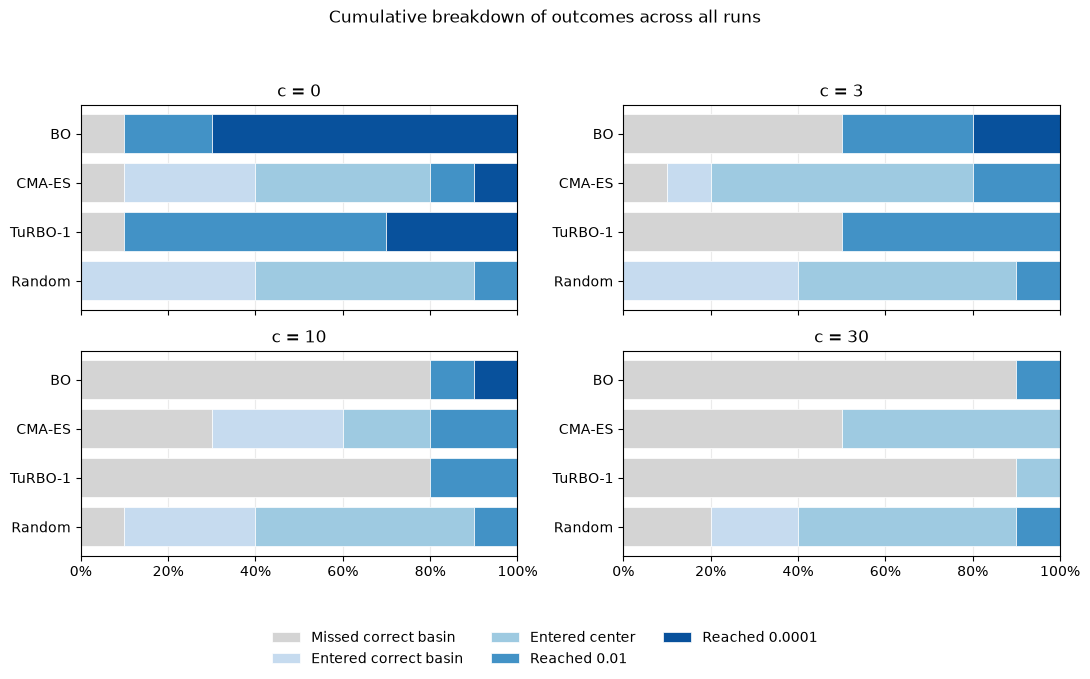

In [15]:
# build target-level rows, aggregate success rates, and derive per-trial search diagnostics.
trials = target_trials(results, ANALYSIS_SETTINGS["targets"])
summary = summarise_targets(trials)
diagnostics = search_diagnostics(results, trials, ANALYSIS_SETTINGS)

order = pd.MultiIndex.from_product([RUN_SETTINGS["c_values"], RUN_SETTINGS["methods"]],
                                   names=["c", "method"])
counts = summary.pivot(index=["c", "method"], columns="target", values="successes")
counts = counts.reindex(index=order, columns=ANALYSIS_SETTINGS["targets"])
sizes = summary.groupby(["c", "method"])["runs"].first().reindex(order)

overview = counts.astype(str).add("/" + sizes.astype(str), axis="index")
overview.columns = ["Beat A", "Entered core", "f < 0.01", "f < 0.0001"]

overview["Median best"] = diagnostics.groupby(["c", "method"])["best"].median().reindex(order)
display(overview.assign(**{"Median best": overview["Median best"].map("{:.4g}".format)}))

trials.to_csv(run_dir / "trials.csv", index=False)
summary.to_csv(run_dir / "summary.csv", index=False)
diagnostics.to_csv(run_dir / "diagnostics.csv", index=False)
overview.to_csv(run_dir / "overview.csv")

plot_outcome_breakdown(summary, RUN_SETTINGS, run_dir)

## 4. Compare results

The first graph shows how success rate changes with $c$, where success is counted with $f<1$. The best-so-far curves use the median and interquartile range across all seeds. The dashed horizontal line marks the value 1
at basin A's minimum.

The concentration plot separates runs that discovered B from runs that missed it. It measures the share of the final evaluations close to A. The table reports the number of runs in each group, since
some groups have only one or two seeds. The table also shows when successful runs discovered B, because a late discovery leaves fewer calls to refine the result.

In [16]:
def plot_target_rates(summary, settings, run_dir):
    penalties = settings["c_values"]
    methods = settings["methods"]
    targets = ANALYSIS_SETTINGS["targets"]
    spacing = min(np.diff(sorted(penalties))) if len(penalties) > 1 else 1.0
    
    # slight horizontal offsets separate datapoints plotted at the same penalty
    offsets = np.linspace(-0.18, 0.18, len(methods)) * spacing if len(methods) > 1 else [0]

    fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
    for ax, target in zip(axes.flat, targets):
        part = summary.loc[summary["target"] == target].set_index(["c", "method"])
        for method, offset in zip(methods, offsets):
            color, marker = METHOD_STYLES[method]
            rates = part.xs(method, level="method").reindex(penalties)["success_probability"]
            ax.plot(np.asarray(penalties) + offset, rates, color=color, marker=marker,
                    label=method, linewidth=1.4)
        ax.set(title=f"$f < {target:g}$", xlabel="Penalty c", ylabel="Fraction of successful runs",
               xticks=penalties, ylim=(-0.05, 1.05))
        ax.grid(alpha=0.3)
    axes.flat[0].legend(fontsize=8)
    fig.suptitle(f"Success rates after {settings['budget']} calls")
    fig.tight_layout()
    save_figure(fig, run_dir, "targets_by_c.png")


def plot_progress(results, diagnostics, settings, run_dir):
    penalties = settings["c_values"]
    methods = settings["methods"]
    budget = settings["budget"]
    calls = np.arange(1, budget + 1)
    histories = {(c, method): [] for c, method in product(penalties, methods)}
    for run in results["runs"]:
        histories[run["c"], run["method"]].append(np.minimum.accumulate(run["y"]))

    fig, axes = plt.subplots(2, len(penalties), figsize=(4 * len(penalties), 6.7),
                             sharex=True, sharey="row", squeeze=False)
    for column, c_value in enumerate(penalties):
        ax_hit, ax_best = axes[:, column]
        for method in methods:
            color, marker = METHOD_STYLES[method]
            first = diagnostics.loc[
                (diagnostics["c"] == c_value) & (diagnostics["method"] == method),
                "first_discovery",
            ].to_numpy()

            cumulative = (first[:, None] <= np.arange(budget + 1)).mean(axis=0)
            ax_hit.step(np.arange(budget + 1), cumulative, where="post", color=color, label=method)
            ax_hit.scatter(budget, cumulative[-1], color=color, marker=marker, s=20)

            lower, median, upper = np.quantile(histories[c_value, method], [0.25, 0.5, 0.75], axis=0)
            ax_best.step(calls, median, where="post", color=color)
            ax_best.fill_between(calls, lower, upper, step="post", color=color, alpha=0.15)

        ax_hit.set(title=f"c = {c_value:g}", xlim=(0, budget + 1), ylim=(-0.03, 1.03))
        ax_best.axhline(1, color="black", linestyle="--", linewidth=0.9)
        ax_best.set(xlabel="Objective evaluations", ylim=(0, None))

        ax_best.set_yscale("symlog", linthresh=1e-5)
        for ax in (ax_hit, ax_best):
            ax.grid(alpha=0.3)
    axes[0, 0].set_ylabel("Fraction of runs that discovered B")
    axes[1, 0].set_ylabel("Median best-so-far objective")
    axes[0, 0].legend(fontsize=8)
    fig.tight_layout()
    save_figure(fig, run_dir, "discovery_and_progress.png")


def plot_concentration(concentration, settings, analysis, run_dir):
    penalties = settings["c_values"]
    methods = settings["methods"]
    spacing = min(np.diff(sorted(penalties))) if len(penalties) > 1 else 1.0
    offsets = np.linspace(-0.18, 0.18, len(methods)) * spacing if len(methods) > 1 else [0]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
    for ax, discovered in zip(axes, (False, True)):
        by_outcome = concentration.loc[concentration["discovered"] == discovered]
        for method, offset in zip(methods, offsets):
            color, marker = METHOD_STYLES[method]
            near_a = by_outcome.loc[by_outcome["method"] == method].set_index("c")
            rates = near_a["mean_late_near_a"].reindex(penalties)
            ax.plot(np.asarray(penalties) + offset, rates, color=color, marker=marker,
                    label=method, linewidth=1.4)
        ax.set(title="Discovered B" if discovered else "Missed B", xlabel="Penalty c",
               xticks=penalties, ylim=(-0.05, 1.05))
        ax.grid(alpha=0.3)
    n = min(analysis["late_evaluations"], settings["budget"])
    radius = analysis["near_a_radius"]
    axes[0].set_ylabel(f"Fraction of final {n} function evaluations within distance {radius:g} of A")
    axes[1].legend(fontsize=8)
    fig.tight_layout()
    save_figure(fig, run_dir, "near_basin_a.png")

,c,method,discovered,runs,mean_late_near_a,median_best
0,0.0,BO,False,1,0.850000,1.000184
1,0.0,BO,True,9,0.016667,0.000009
2,0.0,CMA-ES,False,1,0.450000,1.075840
3,0.0,CMA-ES,True,9,0.038889,0.029974
4,0.0,Random,True,10,0.050000,0.188032
5,0.0,TuRBO-1,False,1,0.800000,1.000228
6,0.0,TuRBO-1,True,9,0.011111,0.000324
7,3.0,BO,False,5,0.830000,1.000076
8,3.0,BO,True,5,0.010000,0.000228
9,3.0,CMA-ES,False,1,0.450000,1.081935


discoveries  median_first_discovery  discoveries_after_half  \
c    method                                                                 
0.0  BO                 9                    12.0                       0   
     CMA-ES             9                     9.0                       2   
     Random            10                     9.5                       1   
     TuRBO-1            9                     7.0                       0   
3.0  BO                 5                     7.0                       0   
     CMA-ES             9                    14.0                       3   
     Random            10                    13.5                       2   
     TuRBO-1            5                     6.0                       0   
10.0 BO                 2                     8.5                       0   
     CMA-ES             7                    28.0                       4   
     Random             9                    22.0                       3   
     TuRBO-1            2                     5.0                       0   
30.0 BO                 1                     9.0                       0   
     CMA-ES             5                    16.0                       2   
     Random             8                    18.0                       2   
     TuRBO-1            1                    50.0                       1   

              median_calls_left  reached_0_01  
c    method                                    
0.0  BO                    38.0             9  
     CMA-ES                41.0             2  
     Random                40.5             1  
     TuRBO-1               43.0             9  
3.0  BO                    43.0             5  
     CMA-ES                36.0             2  
     Random                36.5             1  
     TuRBO-1               44.0             5  
10.0 BO                    41.5             2  
     CMA-ES                22.0             2  
     Random                28.0             1  
     TuRBO-1               45.0             2  
30.0 BO                    41.0             1  
     CMA-ES                34.0             0  
     Random                32.0             1  
     TuRBO-1                0.0             0

CMA-ES started again in 0/40 runs.


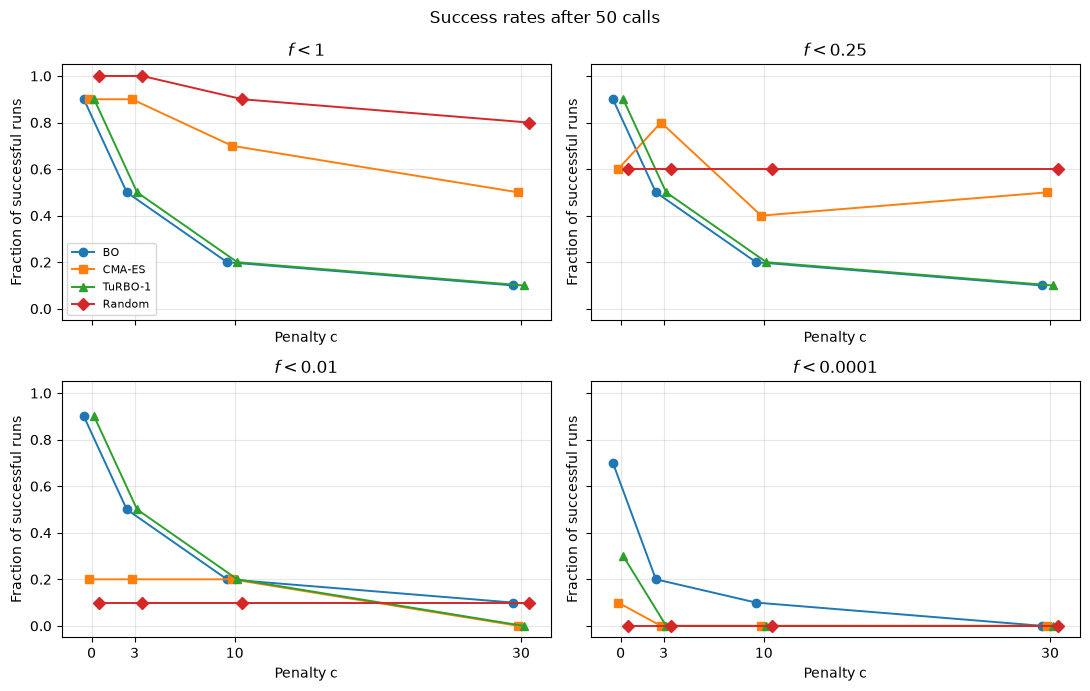

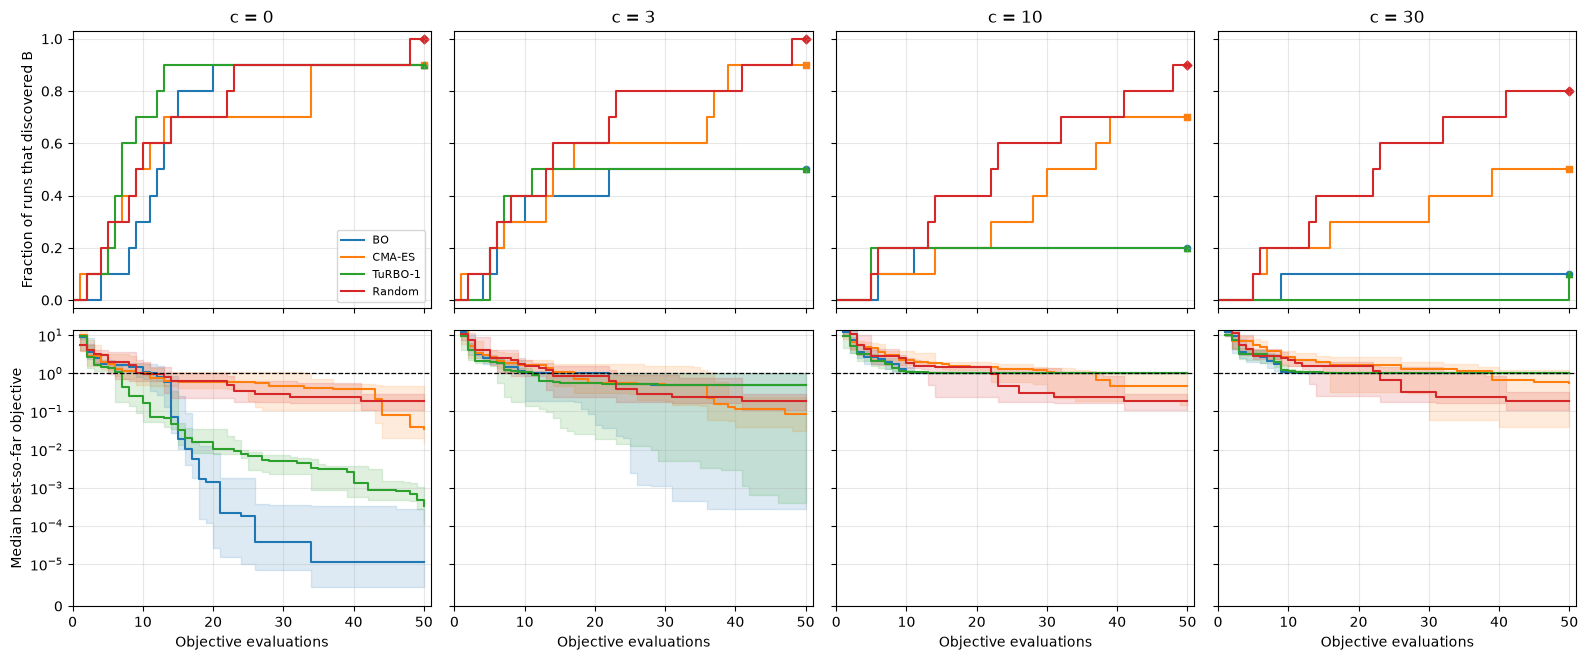

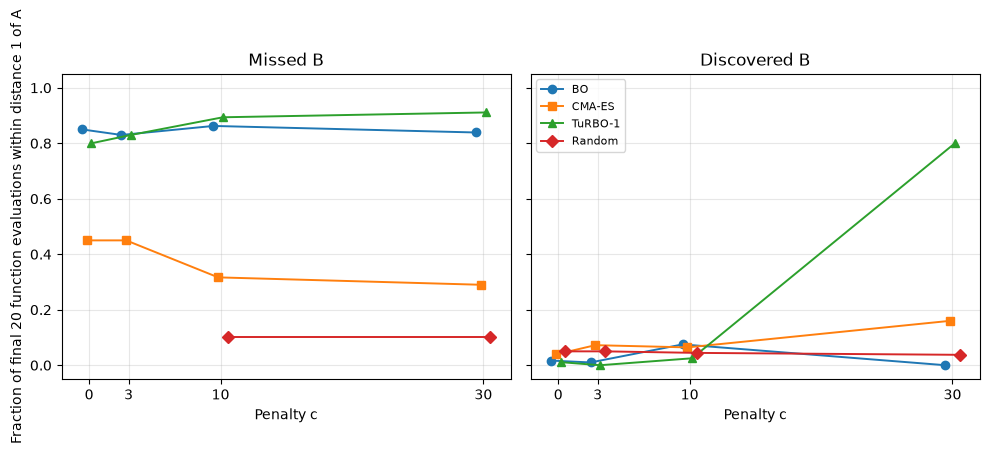

In [17]:
concentration = diagnostics.groupby(["c", "method", "discovered"]).agg(
    runs=("seed", "size"),
    mean_late_near_a=("late_near_a", "mean"),
    median_best=("best", "median"),
).reset_index()

hits = diagnostics.loc[diagnostics["discovered"]].assign(
    reached_0_01=lambda rows: rows["best"] < 0.01,
    hit_after_half=lambda rows: rows["first_discovery"] > RUN_SETTINGS["budget"] / 2,
)

refinement = hits.groupby(["c", "method"]).agg(
    discoveries=("seed", "size"),
    median_first_discovery=("first_discovery", "median"),
    discoveries_after_half=("hit_after_half", "sum"),
    median_calls_left=("calls_after_discovery", "median"),
    reached_0_01=("reached_0_01", "sum"),
)
display(concentration.round(6))
display(refinement)
concentration.to_csv(run_dir / "concentration.csv", index=False)
refinement.to_csv(run_dir / "refinement.csv")

cma_runs = diagnostics.loc[diagnostics["method"] == "CMA-ES", "restarts"].dropna()
if not cma_runs.empty:
    print(f"CMA-ES started again in {(cma_runs > 0).sum()}/{len(cma_runs)} runs.")

plot_target_rates(summary, RUN_SETTINGS, run_dir)
plot_progress(results, diagnostics, RUN_SETTINGS, run_dir)
plot_concentration(concentration, RUN_SETTINGS, ANALYSIS_SETTINGS, run_dir)

## 5. Map trajectories

At the largest $c$, show the lowest-numbered seed in each outcome
group for each optimiser. Both outcomes use the same penalty and the
same selection rule. A panel is labelled if its group has no runs.

Points show objective evaluations, coloured by their evaluation
number. The ring marks the best point found. The dashed red circle
bounds the region where $f<1$, and the dotted red circle marks the
fixed core. 

In [18]:
from matplotlib.patches import Circle

def plot_trajectories(results, settings, c_value, run_dir):
    """Plot one discovered and one missed trajectory per optimiser at the chosen c."""

    methods = [m for m in settings["methods"] if m != "Random"] or settings["methods"]
    problem = settings["problem"]
    a, b = np.asarray(problem["a"]), np.asarray(problem["b"])
    bounds = np.asarray(problem["bounds"])
    r0 = problem["r0"]
    budget = settings["budget"]

    x, y = np.meshgrid(*(np.linspace(lo, hi, 250) for lo, hi in bounds))
    d_a = np.hypot(x - a[0], y - a[1])
    d_b = np.hypot(x - b[0], y - b[1])
    values = np.minimum(1 + d_a**2, d_b**2 + c_value * np.maximum(0, d_b - r0)**2)

    discovery_radius = 1.0
    if r0 < 1:
        discovery_radius = (c_value * r0 + np.sqrt(1 + c_value * (1 - r0**2))) / (1 + c_value)
        
    norm = plt.Normalize(1, max(2, budget))
    palette = "viridis"

    fig, axes = plt.subplots(2, len(methods), figsize=(4 * len(methods) + 0.5, 8),
                             squeeze=False, constrained_layout=True)
    fig.get_layout_engine().set(h_pad=0.12)
    runs = [run for run in results["runs"] if run["c"] == c_value]
    for col, method in enumerate(methods):

        candidates = sorted((run for run in runs if run["method"] == method),
                            key=lambda run: run["seed"])
        for row, discovered in enumerate((False, True)):
            ax = axes[row, col]
            ax.contour(x, y, values, levels=[0.05, 0.25, 0.5, 1, 2, 4, 8, 16, 32],
                       colors="0.82", linewidths=0.65)
            ax.add_patch(Circle(b, discovery_radius, fill=False, color="tab:red", ls="--", lw=1.1))
            ax.add_patch(Circle(b, r0, fill=False, color="tab:red", ls=":", lw=1.1))
            ax.scatter(*a, color="black", marker="X", s=52, zorder=3)
            ax.scatter(*b, color="tab:red", marker="*", s=90, zorder=3)
            outcome = "Discovered B" if discovered else "Missed B"

            run = next((r for r in candidates if (min(r["y"]) < 1) == discovered), None)
            if run is None:
                ax.set_title(f"{method}, {outcome}\nNo example")
            else:
                points = np.asarray(run["X"])
                history = np.asarray(run["y"])
                best = int(np.argmin(history))
                ax.scatter(*points.T, c=np.arange(1, len(points) + 1), cmap=palette, norm=norm,
                           s=24, alpha=0.9, zorder=4)

                ax.scatter(*points[best], facecolors="none", edgecolors="black",
                           s=105, linewidths=1, zorder=5)
                hits = np.flatnonzero(history < 1)
                hit = f" · first hit {hits[0] + 1}" if hits.size else ""
                ax.set_title(f"{method},{outcome},seed {run['seed']}\n"
                             f"best = {history[best]:.6g}{hit}")
            ax.set(xlim=bounds[0], ylim=bounds[1], aspect="equal", ylabel="$x_2$")
            if row == 1:
                ax.set_xlabel("$x_1$")
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=palette), ax=axes,
                 shrink=0.72, label="Evaluation number")
    fig.suptitle(f"Example search trajectories at c = {c_value:g}")
    save_figure(fig, run_dir, "trajectories.png")

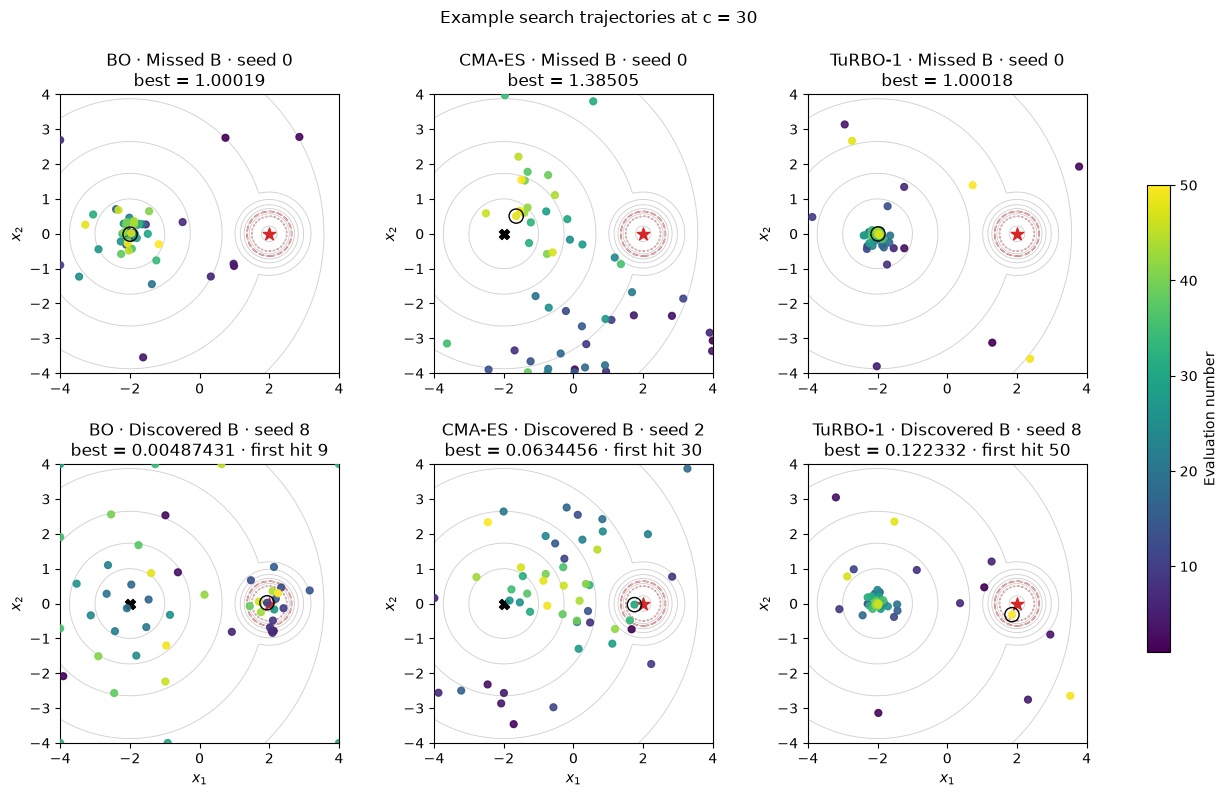

In [11]:
# Compare example outcomes at the largest configured penalty, where discovery is hardest.
trajectory_c = max(RUN_SETTINGS["c_values"])
plot_trajectories(results, RUN_SETTINGS, trajectory_c, run_dir)